# **01 - Exploratory Data Analysis (EDA)**

1. **Setup dan lokasi data**

Mengimpor library dasar, menetapkan nama kompetisi (dari kaggle), lalu mencari folder dataset di Kaggle. Data kompetisi ter-*mount* di `/kaggle/input/competitions/<slug>` (kode juga mencoba lokasi alternatif). Variabel `WORK` adalah folder keluaran (`/kaggle/working`), `CLASS_NAMES` adalah 16 kelas sesuai urutan `label` 0-15, dan `SEED` dipakai agar hasil bisa diulang.

**Hasil:** `DATA_DIR` terdeteksi di `/kaggle/input/competitions/document-image-classification-sd234504`.

In [ ]:
import os, time, random, warnings, glob
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

COMP = "document-image-classification-sd234504"
CANDIDATES = [Path(f"/kaggle/input/{COMP}"), Path(f"/kaggle/input/competitions/{COMP}")]
DATA_DIR = next((p for p in CANDIDATES if (p / "train.csv").exists()), None)
if DATA_DIR is None:
    hits = [h for pat in ("*/train.csv", "*/*/train.csv", "*/*/*/train.csv") for h in glob.glob("/kaggle/input/" + pat)]
    assert hits, "Dataset kompetisi belum ditambahkan! Klik 'Add Input' -> tab Competition."
    DATA_DIR = Path(hits[0]).parent
WORK = Path("/kaggle/working")
CLASS_NAMES = ["advertisement", "budget", "email", "file_folder", "form", "handwritten",
               "invoice", "letter", "memo", "news_article", "presentation", "questionnaire",
               "resume", "scientific_publication", "scientific_report", "specification"]
SEED = 42
print("DATA_DIR:", DATA_DIR)

DATA_DIR: /kaggle/input/competitions/document-image-classification-sd234504


2. **Fungsi `resolve_path`**

Kolom `filename` di CSV berisi path relatif seperti `train/resume/xxx.tif`, sedangkan folder di disk bisa bersarang (mis. `train/train/...`). Fungsi ini mencoba kedua lokasi sehingga setiap gambar pasti ditemukan.

In [ ]:
def resolve_path(root, filename):
    """Mencari lokasi file gambar di disk.

    CSV menulis ``train/invoice/x.tif`` sedangkan di disk bisa ``train/train/invoice/x.tif``.

    Args:
        root: Folder dataset.
        filename: Kolom ``filename`` dari CSV.

    Returns:
        Path file yang ditemukan.
    """
    root = Path(root)
    for p in (root / filename, root / filename.split("/")[0] / filename):
        if p.exists():
            return p
    raise FileNotFoundError(f"{filename} tidak ditemukan di {root}")

3. **Struktur data**

Membaca `train.csv`, `test.csv`, dan `sample_submission.csv`, lalu menampilkan ukuran dan beberapa baris awal.

**Hasil:** 32.003 gambar latih (kolom `id`, `filename`, `class_name`, `label`), 7.994 gambar uji (hanya `id` dan `filename`), dan `sample_submission` berisi 7.994 baris. Seluruh gambar test harus diprediksi, satu label (0-15) per `id`.

In [ ]:
train = pd.read_csv(DATA_DIR / "train.csv"); test = pd.read_csv(DATA_DIR / "test.csv")
sample = pd.read_csv(DATA_DIR / "sample_submission.csv")
print("train:", train.shape, "| test:", test.shape, "| sample_submission:", sample.shape)
train.head()

train: (32003, 4) | test: (7994, 2) | sample_submission: (7994, 2)


,id,filename,class_name,label
0,train_00001,train/resume/50497291-7292.tif,resume,12
1,train_00002,train/scientific_publication/50728670-8670.tif,scientific_publication,13
2,train_00003,train/scientific_report/87112192.tif,scientific_report,14
3,train_00004,train/scientific_publication/10343650_10343655...,scientific_publication,13
4,train_00005,train/specification/2057960699_2057960701.tif,specification,15


4. **Distribusi kelas**

Menghitung jumlah gambar per kelas dan menampilkannya sebagai tabel serta diagram batang horizontal.

**Hasil:** kelas **sangat seimbang**, dari 1.948 (*questionnaire*) sampai 2.056 (*scientific_publication*), selisih sekitar 5%. Tidak perlu *class weighting* atau *resampling*, dan akurasi cukup adil sebagai metrik. Tebakan acak setara sekitar 6,25%.

 label             class_name    n
     0          advertisement 2012
     1                 budget 2004
     2                  email 2013
     3            file_folder 2022
     4                   form 2005
     5            handwritten 2026
     6                invoice 1982
     7                 letter 1972
     8                   memo 1994
     9           news_article 1971
    10           presentation 1992
    11          questionnaire 1948
    12                 resume 2029
    13 scientific_publication 2056
    14      scientific_report 1999
    15          specification 1978


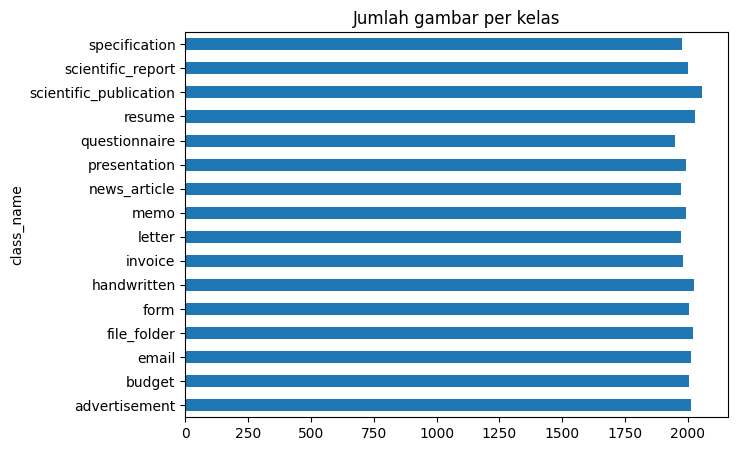

In [ ]:
counts = train.groupby(["label", "class_name"]).size().reset_index(name="n")
print(counts.to_string(index=False))
train.class_name.value_counts().sort_index().plot.barh(figsize=(7, 5), title="Jumlah gambar per kelas")
plt.show()

5. **Contoh gambar tiap kelas**

Menampilkan satu gambar acak per kelas (grayscale) untuk melihat karakter visual data.

**Pengamatan:**
- Dokumen berupa pindaian berkualitas rendah: noise, tepi hitam, teks kabur.
- Kelas dengan ciri jelas: *advertisement*, *handwritten*, *email*, *resume*, *questionnaire*.
- Kelas yang tata letaknya mirip dan berpotensi tertukar: *letter*, *memo*, *form*, *scientific_report*, *scientific_publication*, *presentation*.
- *File_folder* pada sampel ini hampir kosong dengan noise, dan beberapa dokumen cetak berisi tanda tangan atau coretan tangan.
- Semua gambar berorientasi potret. Hasil ini dari satu sampel acak per kelas, bukan seluruh data.

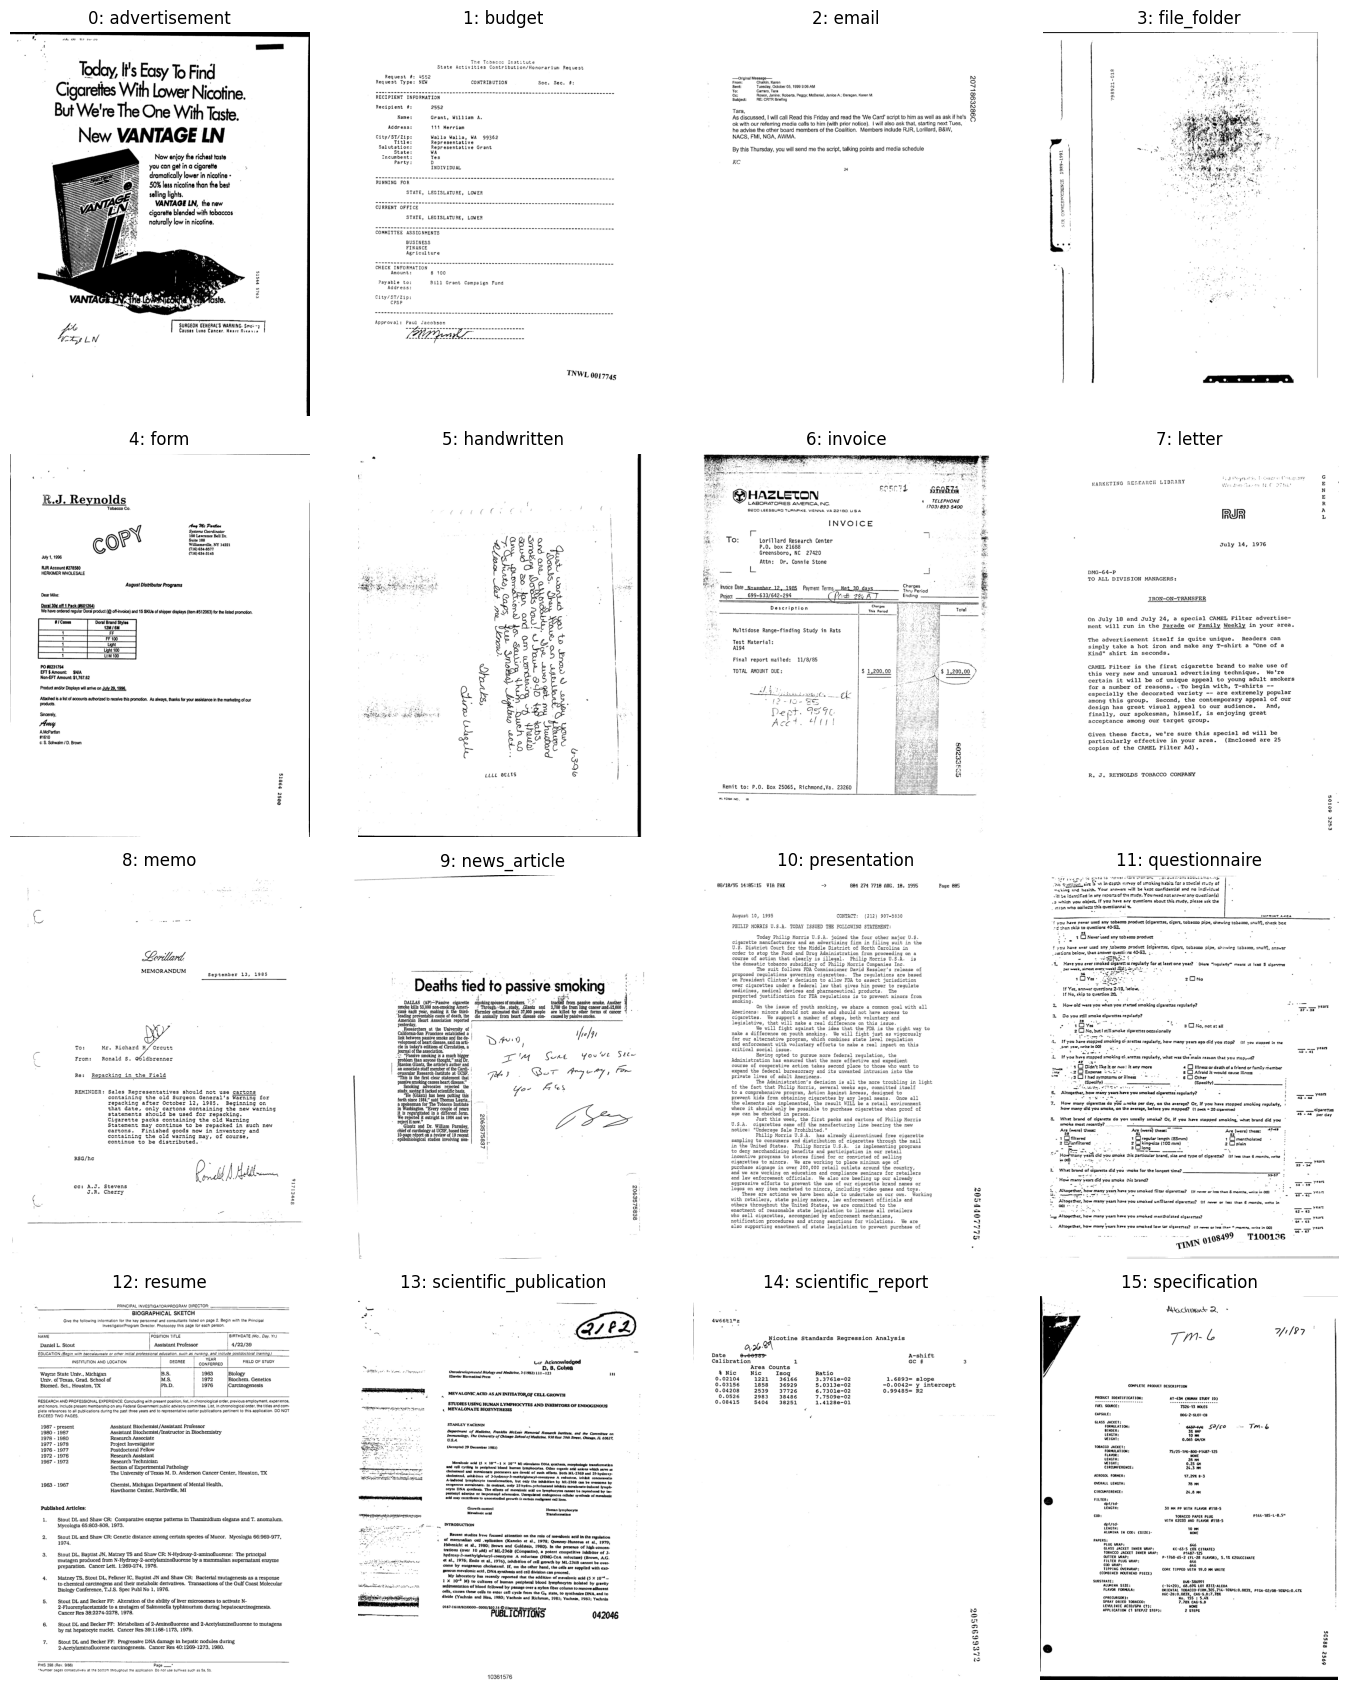

In [ ]:
fig, axes = plt.subplots(4, 4, figsize=(14, 17))
for ax, (i, name) in zip(axes.ravel(), enumerate(CLASS_NAMES)):
    row = train[train.label == i].sample(1, random_state=0).iloc[0]
    ax.imshow(Image.open(resolve_path(DATA_DIR, row.filename)).convert("L"), cmap="gray")
    ax.set_title(f"{i}: {name}"); ax.axis("off")
plt.tight_layout(); plt.show()

6. **Pemeriksaan file terpotong atau korup**

Membaca ukuran setiap file train dan test. File berukuran 0 byte atau tepat 32.768 byte (32 KB) biasanya tanda terpotong saat unduh atau ekstraksi.

**Hasil:** train memiliki 0 file kosong dan **1 file** 32.768 byte (sekitar 0,003%), test tidak memiliki file bermasalah. Median ukuran file hampir sama (train sekitar 99,9 KB, test sekitar 98,8 KB), menandakan train dan test berasal dari distribusi serupa. Satu file korup ditangani oleh `load_image` (diganti halaman putih).

In [ ]:
def scan(df):
    sz = [os.path.getsize(resolve_path(DATA_DIR, f)) for f in tqdm(df.filename)]
    return pd.Series(sz)
tr_sz, te_sz = scan(train), scan(test)
print("train -> 0 byte:", (tr_sz == 0).sum(), "| 32768 byte:", (tr_sz == 32768).sum())
print("test  -> 0 byte:", (te_sz == 0).sum(), "| 32768 byte:", (te_sz == 32768).sum())
print("ukuran file median (KB): train", tr_sz.median() / 1024, "| test", te_sz.median() / 1024)

train -> 0 byte: 0 | 32768 byte: 1
test  -> 0 byte: 0 | 32768 byte: 0
ukuran file median (KB): train 99.923828125 | test 98.8203125


7. **Kesimpulan EDA dan implikasi**

| Aspek | Temuan |
|---|---|
| Ukuran data | 32.003 latih, 7.994 uji, 16 kelas |
| Keseimbangan kelas | Sangat seimbang (1.948 - 2.056 per kelas) |
| Kualitas data | Hampir bersih: 1 file train terpotong, 0 di test |
| Train vs test | Serupa (median ukuran file ~100 KB vs ~99 KB) |
| Karakter citra | Pindaian grayscale, potret, ber-noise |
| Tantangan utama | Kelas dengan tata letak mirip |

**Keputusan desain:** gambar diubah ke grayscale 224x224 dan di-*cache*; augmentasi geser kecil (tanpa flip karena merusak arah baca); validasi *stratified* 90:10 dengan seed tetap; backbone Transformer pre-trained pada dokumen (DiT) di-*fine-tune*. 

**Keterbatasan:** resize ke 224 mengurangi keterbacaan teks kecil yang kadang menjadi pembeda antar kelas.